Active Sources: 2, Total Spend: $70.00 / $70.00
Covered Points: 13 / 30 (Weighted Score: 81.0)


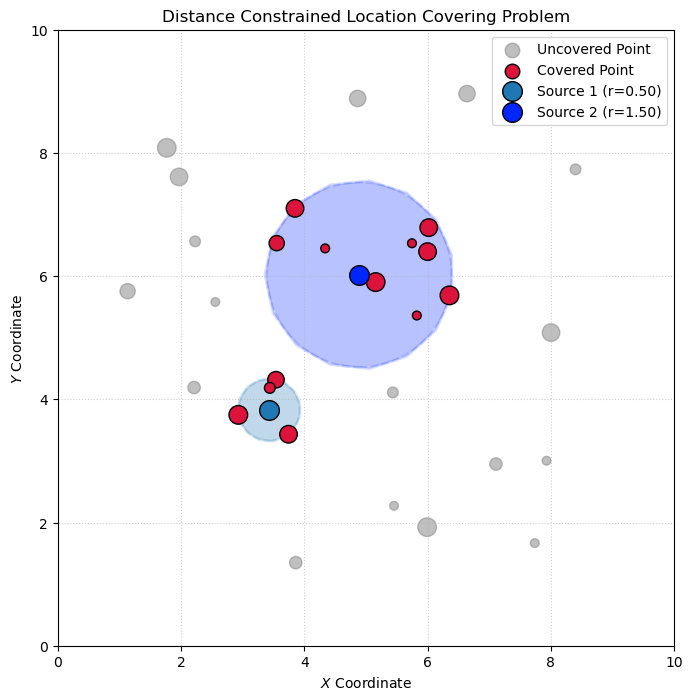

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo
import networkx as nx

k = 30 # Demand points
s = 4 # Number of potential source locations
budget = 70 # Total budget to cover points
c_fixed = 25 # Fixed start-up cost
c_var = 10 # Variable cost associated with distance 
max_distance = 1.5 # maximum distance per source
number_of_cuts = 15 
BigM = 15  
points = {i: (np.random.uniform(1, 9), np.random.uniform(1, 9)) for i in range(k)}
weights = {i: float(np.random.randint(1, 10)) for i in range(k)}
angles = [2 * np.pi * m / number_of_cuts for m in range(number_of_cuts)]

def obj_rule(model):
    return sum(weights[i] * model.y[i] for i in model.I)

def budget_rule(model): 
    return (sum(c_fixed * model.u[j] + c_var * model.r[j] for j in model.J)<= budget)

def distance_rule(model, i, j, m):
    """ Facility Location j; Demand Location i; Approximate Curve m"""
    px, py = points[i]
    theta = angles[m]
    return (model.x1[j] - px) * np.cos(theta) + (model.x2[j] - py) * np.sin(theta) <= model.r[j] + BigM * (1 - model.z[i, j])

def radius_activation_rule(model, j):
    return model.r[j] <= max_distance * model.u[j]

def x1_activation_rule(model, j):
    return model.x1[j] <= 10 * model.u[j]

def x2_activation_rule(model, j):
    return model.x2[j] <= 10 * model.u[j]

def coverage_activation_rule(model, i, j):
    return model.z[i, j] <= model.u[j]

def coverage_link_rule(model, i):
    return sum(model.z[i, j] for j in model.J) >= model.y[i]

model = pyo.ConcreteModel(name="MaxCoverage_Linearized")
model.I = pyo.Set(initialize=range(k))
model.J = pyo.Set(initialize=range(s))
model.M = pyo.Set(initialize=range(number_of_cuts))

model.x1 = pyo.Var(model.J, domain=pyo.Reals, bounds=(0, 10))
model.x2 = pyo.Var(model.J, domain=pyo.Reals, bounds=(0, 10))
model.r = pyo.Var(model.J, domain=pyo.NonNegativeReals, bounds=(0, max_distance))
model.u = pyo.Var(model.J, domain=pyo.Binary)
model.y = pyo.Var(model.I, domain=pyo.Binary)
model.z = pyo.Var(model.I, model.J, domain=pyo.Binary)

model.obj = pyo.Objective(rule=obj_rule, sense=pyo.maximize)
model.dist_con = pyo.Constraint(model.I, model.J, model.M, rule=distance_rule)
model.rad_act_con = pyo.Constraint(model.J, rule=radius_activation_rule)
model.budget_con = pyo.Constraint(rule=budget_rule)
model.cover_link_con = pyo.Constraint(model.I, rule=coverage_link_rule)
model.x1_act = pyo.Constraint(model.J, rule=x1_activation_rule)
model.x2_act = pyo.Constraint(model.J, rule=x2_activation_rule)
solver = pyo.SolverFactory('appsi_highs')
results = solver.solve(model)
active_sources = [j for j in model.J if pyo.value(model.u[j]) > 0.5]
covered_indices = [i for i in model.I if pyo.value(model.y[i]) > 0.5]
uncovered_indices = [i for i in model.I if pyo.value(model.y[i]) <= 0.5]
total_cost = sum(c_fixed * pyo.value(model.u[j]) + c_var * pyo.value(model.r[j])for j in model.J)
print(f"Active Sources: {len(active_sources)}, Total Spend: ${total_cost:.2f} / ${budget:.2f}")
print(f"Covered Points: {len(covered_indices)} / {k} (Weighted Score: {pyo.value(model.obj):.1f})")
fig, ax = plt.subplots(figsize=(8, 8))

# Uncovered points
uncovered_pts = np.array([points[i] for i in uncovered_indices])
if len(uncovered_pts) > 0:
    ax.scatter(uncovered_pts[:, 0], uncovered_pts[:, 1], c="gray",s=[weights[i] * 20 for i in uncovered_indices], alpha=0.5,label="Uncovered Point",)

# Covered points
covered_pts = np.array([points[i] for i in covered_indices])
if len(covered_pts) > 0:
    ax.scatter(covered_pts[:, 0],covered_pts[:, 1], c="crimson",s=[weights[i] * 20 for i in covered_indices], edgecolors="black",zorder=3,label="Covered Point",)

# Plot facilites
colors = ["#1f77b4", "#0026ff", "#0065e0", "#008486"]
for idx, j in enumerate(active_sources):
    xj1 = pyo.value(model.x1[j])
    xj2 = pyo.value(model.x2[j])
    rj = pyo.value(model.r[j])
    col = colors[idx % len(colors)]
    ax.scatter(xj1,xj2,c=col,s=200,edgecolors='black',zorder=5,label=f"Source {j+1} (r={rj:.2f})")
    circle = plt.Circle((xj1, xj2),rj,color=col,fill=True,alpha=0.15,linestyle="--",linewidth=1.5,)
    ax.add_patch(circle)


    vertex_angles = np.array(angles) + (np.pi / number_of_cuts)
    r_vertex = rj / np.cos(np.pi / number_of_cuts)

    poly_x = xj1 + r_vertex * np.cos(vertex_angles)
    poly_y = xj2 + r_vertex * np.sin(vertex_angles)
    ax.fill(poly_x, poly_y, color=col, alpha=0.15, linewidth=2, edgecolor=col, linestyle="-",)

# Formatting
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.6)
ax.set_xlabel("$X$ Coordinate")
ax.set_ylabel("$Y$ Coordinate")
ax.set_title("Distance Constrained Location Covering Problem")
ax.legend(bbox_to_anchor=(1,1))
plt.show()

$ Min \displaystyle\sum_{(i,j) \in A} u_{ij}\theta_{ij}$

$ s.t. \ \alpha_i - \alpha_j + \theta_{ij} \geq 0 \ \forall \ (i,j) \in A$

$ \alpha_t - \alpha_s \geq 1$

$ \alpha_i \in \{0,1\} \ \forall \ i \in N$

$\theta_{ij} \in  \{0,1\} \ \forall \ (i,j) \in A$



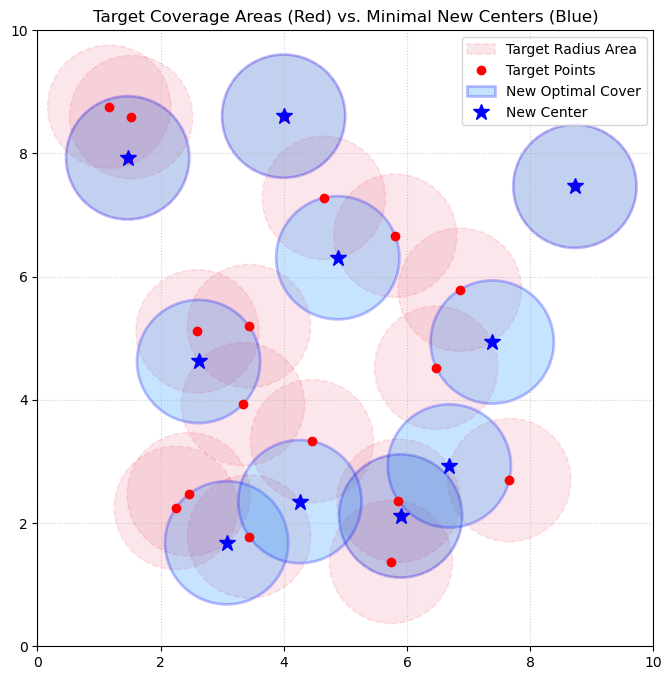

In [17]:
from scipy.optimize import milp, LinearConstraint
from scipy.spatial.distance import cdist
from itertools import combinations

def get_candidate_centers(points, radius=1.0):
    candidates = []
    # Single points
    for p in points:
        candidates.append(p)
    # Pairs of points
    for p1, p2 in combinations(points, 2):
        d = np.linalg.norm(p1 - p2)
        if 0 < d <= 2 * radius:
            mid = (p1 + p2) / 2.0
            h = np.sqrt(radius**2 - (d / 2.0)**2)
            dx, dy = (p2 - p1) / d
            normal = np.array([-dy, dx])
            candidates.append(mid + h * normal)
            candidates.append(mid - h * normal)
    # Triplets of points
    for p1, p2, p3 in combinations(points, 3):
        A = np.array([[p2[0] - p1[0], p2[1] - p1[1]], [p3[0] - p1[0], p3[1] - p1[1]]])
        b = np.array([((p2[0]**2 - p1[0]**2) + (p2[1]**2 - p1[1]**2)) / 2.0, ((p3[0]**2 - p1[0]**2) + (p3[1]**2 - p1[1]**2)) / 2.0])
        if np.abs(np.linalg.det(A)) > 1e-5:
            center = np.linalg.solve(A, b)
            if np.linalg.norm(center - p1) <= radius + 1e-5:
                candidates.append(center)
    return np.array(candidates)

np.random.seed(42)
num_targets = 20
radius = 1.0
target_points = np.random.uniform(1, 9, (num_targets, 2))

candidate_centers = get_candidate_centers(target_points, radius=radius)
dist_matrix = cdist(candidate_centers, target_points)
coverage_matrix = (dist_matrix <= radius + 1e-5).astype(int)

num_candidates = len(candidate_centers)
c = np.ones(num_candidates)
constraints = LinearConstraint(coverage_matrix.T, lb=np.ones(num_targets), ub=np.inf)
integrality = np.ones(num_candidates)

res = milp(c=c, integrality=integrality, constraints=constraints)
selected_indices = np.where(res.x > 0.5)[0]
new_centers = candidate_centers[selected_indices]

fig, ax = plt.subplots(figsize=(8, 8))

# 1. Original target circles around the red points
for i, (tx, ty) in enumerate(target_points):
    circle_target = plt.Circle((tx, ty), radius, color="crimson", alpha=0.1, ec="red", lw=1.2, ls="--", fill=True, label="Target Radius Area" if i == 0 else "")
    ax.add_patch(circle_target)

# Draw target points
ax.plot(target_points[:, 0], target_points[:, 1], "ro", label="Target Points", zorder=3)

# 2. Optimal NEW coverage circles
for i, (cx, cy) in enumerate(new_centers):
    circle_new = plt.Circle((cx, cy), radius, color="dodgerblue", alpha=0.25, ec="blue", lw=2, fill=True, label="New Optimal Cover" if i == 0 else "")
    ax.add_patch(circle_new)
    ax.plot(cx, cy, "b*", markersize=12, label="New Center" if i == 0 else "", zorder=4)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.6)
ax.set_title(f"Target Coverage Areas (Red) vs. Minimal New Centers (Blue)", fontsize=12)
ax.legend(loc="upper right")

plt.savefig('combined_cover.png', bbox_inches='tight')

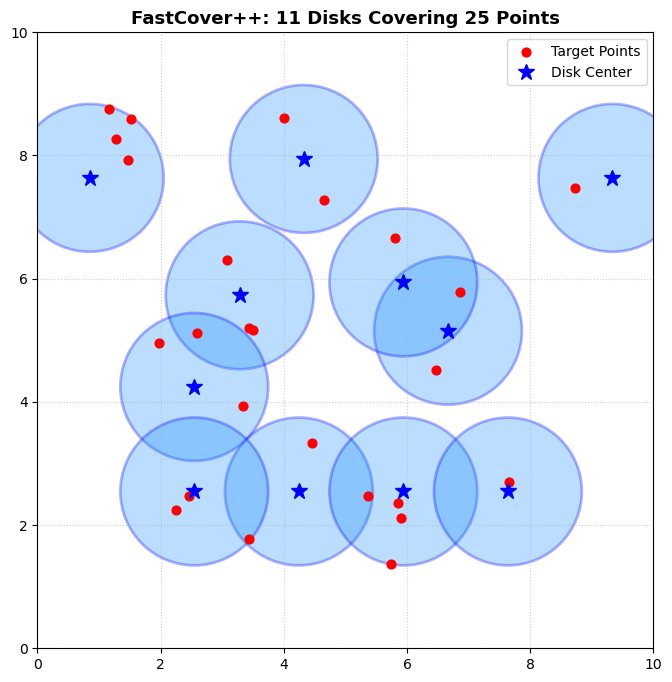

In [18]:
class FastCoverPlusPlus:

    def __init__(self, radius=1.0):
        self.R = radius
        self.H = set()
        self.B = {}
        self.disk_centers = []

    def distance(self, p1, p2):
        return np.sqrt((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2)

    def update_bounding_box(self, key, p):
        if key not in self.B:
            self.B[key] = [p[0], p[1], p[0], p[1]]
        else:
            bb = self.B[key]
            self.B[key] = [min(bb[0], p[0]), min(bb[1], p[1]), max(bb[2], p[0]), max(bb[3], p[1]),]

    def solve(self, P):
        R = self.R
        cell_size = np.sqrt(2) * R
        offset = R / np.sqrt(2)

        # 1. Scaled Grid-disk Assignment
        for p in P:
            px, py = p[0], p[1]
            i = int(np.floor(px / cell_size))
            j = int(np.floor(py / cell_size))

            if (i, j) in self.H:
                self.update_bounding_box((i, j), p)
            elif (
                (px >= cell_size * (i + 1.5) - R) and ((i + 1, j) in self.H) and (self.distance(p, (cell_size * (i + 1) + offset, cell_size * j + offset)) <= R)
                ): 
                self.update_bounding_box((i + 1, j), p)
            elif ((px <= cell_size * (i - 0.5) + R) and ((i - 1, j) in self.H) and (self.distance(p, (cell_size * (i - 1) + offset, cell_size * j + offset)) <= R)):
                self.update_bounding_box((i - 1, j), p)
            elif ((py >= cell_size * (j + 1.5) - R) and ((i, j + 1) in self.H) and (self.distance(p, (cell_size * i + offset, cell_size * (j + 1) + offset)) <= R)):
                self.update_bounding_box((i, j + 1), p)
            elif ((py <= cell_size * (j - 0.5) + R) and ((i, j - 1) in self.H) and (self.distance(p, (cell_size * i + offset, cell_size * (j - 1) + offset)) <= R)):
                self.update_bounding_box((i, j - 1), p)
            else:
                self.H.add((i, j))
                self.update_bounding_box((i, j), p)

        # 2. Pairwise Cell Merging (Diagonal <= 2 * R)
        unconsidered = set(self.H)
        while len(unconsidered) > 0:
            (i, j) = unconsidered.pop()
            merged = False
            for k in range(i - 1, i + 2):
                for l in range(j - 1, j + 2):
                    if (k, l) == (i, j):
                        continue
                    if (k, l) in self.H:
                        bb1 = self.B[(i, j)]
                        bb2 = self.B[(k, l)]
                        merged_bb = [min(bb1[0], bb2[0]), min(bb1[1], bb2[1]), max(bb1[2], bb2[2]), max(bb1[3], bb2[3]),]
                        diag_len = np.sqrt((merged_bb[2] - merged_bb[0]) ** 2 + (merged_bb[3] - merged_bb[1]) ** 2)
                        if diag_len <= 2.0 * R:
                            center = ((merged_bb[0] + merged_bb[2]) / 2.0, (merged_bb[1] + merged_bb[3]) / 2.0,)
                            self.disk_centers.append(center)
                            self.H.remove((i, j))
                            self.H.remove((k, l))
                            unconsidered.discard((k, l))
                            merged = True
                            break
                if merged:
                    break

        # 3. Canonical Grid Disks
        for i, j in self.H:
            center = (cell_size * i + offset, cell_size * j + offset)
            self.disk_centers.append(center)

        return self.disk_centers

# Example run with a custom radius R = 1.8
np.random.seed(42)
points = np.random.uniform(1, 9, (25, 2))
custom_radius = 1.2
solver = FastCoverPlusPlus(radius=custom_radius)
centers = solver.solve(points)

# Plot Results
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(points[:, 0], points[:, 1], c="red", s=40, label="Target Points", zorder=3)
for idx, (cx, cy) in enumerate(centers):
    circle = plt.Circle((cx, cy), custom_radius, color="dodgerblue", alpha=0.3, ec="blue", lw=2)
    ax.add_patch(circle)
    ax.plot(cx, cy, "b*", markersize=12, label="Disk Center" if idx == 0 else "", zorder=4,)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.6)
ax.set_title(f"FastCover++: {len(centers)} Disks Covering {len(points)} Points", fontsize=13,weight="bold")
ax.legend(loc="upper right")
plt.show()

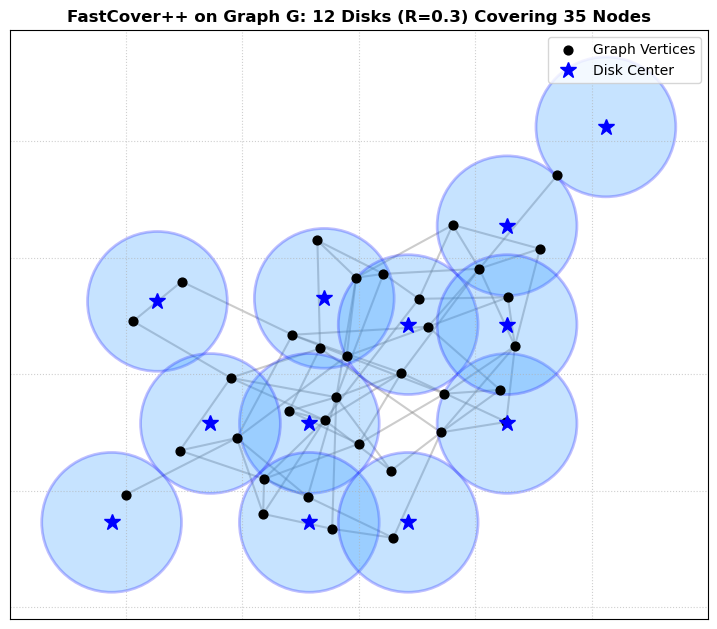

In [19]:
# 1. Generate Graph G
G = nx.erdos_renyi_graph(n=35, p=0.12, seed=42)

# 2. Extract 2D Node Coordinates via Spring Layout
pos = nx.spring_layout(G, seed=42)
node_points = np.array([pos[node] for node in G.nodes()])

# 3. Solve Geometric Disk Covering
custom_radius = 0.3
solver = FastCoverPlusPlus(radius=custom_radius)
centers = solver.solve(node_points)

# 4. Plot Graph and Disk Covers
fig, ax = plt.subplots(figsize=(9, 9))

# Draw Graph Edges and Vertices
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4, edge_color="gray", width=1.5)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color="black", node_size=40, label="Graph Vertices")

# Overlay FastCover++ Disks
for idx, (cx, cy) in enumerate(centers):
    circle = plt.Circle((cx, cy), custom_radius, color="dodgerblue", alpha=0.25, ec="blue", lw=2,)
    ax.add_patch(circle)
    ax.plot(cx, cy, "b*", markersize=12, label="Disk Center" if idx == 0 else "", zorder=4,)

ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.6)
ax.set_title(f"FastCover++ on Graph G: {len(centers)} Disks (R={custom_radius}) Covering {len(G.nodes())} Nodes", fontsize=12, weight="bold",)
ax.legend(loc="upper right")
plt.show()

In [20]:
def distance_node_to_edge_line(p_node, p_u, p_v):
    """Calculates perpendicular distance from p_node to the infinite line through p_u and p_v."""
    edge_vec = p_v - p_u
    edge_len = np.linalg.norm(edge_vec)
    if edge_len == 0:
        return np.linalg.norm(p_node - p_u), 0.0
    # Cross product magnitude divided by edge length gives perpendicular distance
    perp_dist = np.abs((p_v[0] - p_u[0]) * (p_u[1] - p_node[1]) - (p_u[0] - p_node[0]) * (p_v[1] - p_u[1])) / edge_len
    # Projection parameter t along the edge vector
    t = np.dot(p_node - p_u, edge_vec) / (edge_len**2)
    return perp_dist, t

def select_valid_pairs(G, pos, max_distance):
    """Finds all (node, edge) pairs in G where perpendicular distance < max_distance."""
    valid_pairs = []
    for node in G.nodes():
        p_node = np.array(pos[node])
        for u, v in G.edges():
            # Skip edges directly connected to the node itself
            if node == u or node == v:
                continue
            p_u, p_v = np.array(pos[u]), np.array(pos[v])
            dist, t = distance_node_to_edge_line(p_node, p_u, p_v)
            # Condition: Perpendicular distance < 2D and projection falls on segment (0 <= t <= 1)
            if dist < 2*max_distance and 0 <= t <= 1:
                valid_pairs.append({"node": node, "edge": (u, v), "distance": dist})
    return valid_pairs

def find_additional_edge_locations(G, pos, max_distance=5.0):
    """Calculates additional points on edges where the perpendicular distance from a node to the edge is <= max_distance."""
    new_edge_locations = []
    for node in G.nodes():
        p_node = np.array(pos[node])
        for u, v in G.edges():
            # Skip edges that share this node as an endpoint
            if node == u or node == v:
                continue
            p_u = np.array(pos[u])
            p_v = np.array(pos[v])
            edge_vec = p_v - p_u
            edge_len_sq = np.dot(edge_vec, edge_vec)
            if edge_len_sq == 0:
                continue
            # Calculate parameter t (projection along edge segment)
            t = np.dot(p_node - p_u, edge_vec) / edge_len_sq
            # Ensure the normal projection falls ON the edge segment [0, 1]
            if 0 <= t <= 1:
                # Point on the edge where normal meets node n
                p_edge = p_u + t * edge_vec
                perp_dist = np.linalg.norm(p_node - p_edge)
                if perp_dist <= 2*max_distance:
                    new_edge_locations.append({"point": tuple(p_edge), "target_node": node, "edge": (u, v), "distance": perp_dist, "t": t,})
    return new_edge_locations

Total Raw Edge Projections: 110
Dominant Edge Projections:  76


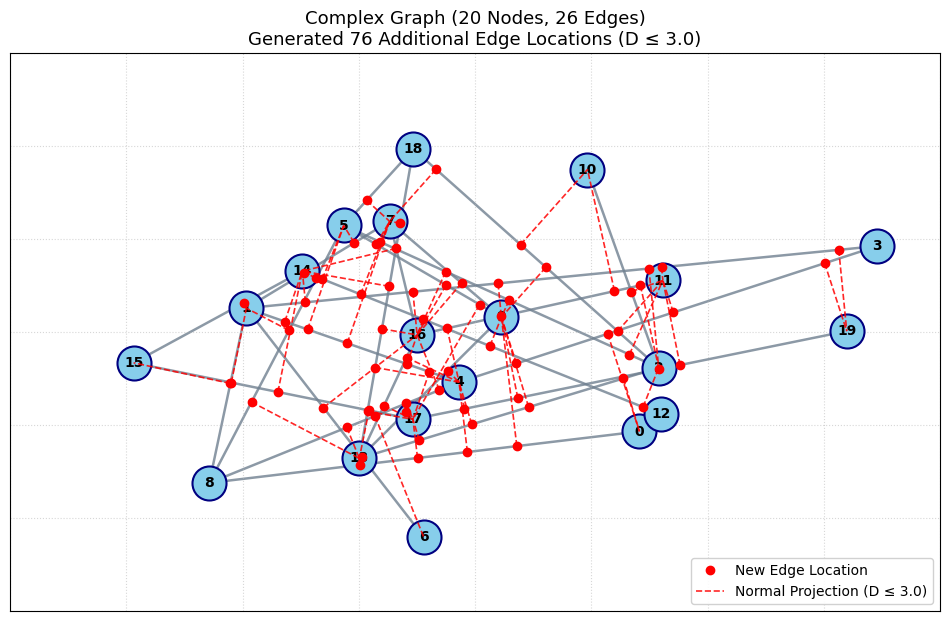

In [21]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


# Graph Generation
def generate_graph(num_nodes=20, seed=123):
    """Generates a connected Waxman spatial random graph with 2D positions."""
    np.random.seed(seed)
    G = nx.waxman_graph(num_nodes, beta=0.4, alpha=0.3, seed=seed)

    # Assign 2D coordinates to nodes
    pos = {i: (np.random.uniform(1, 19), np.random.uniform(1, 11)) for i in G.nodes()}

    # Ensure the graph is fully connected
    if not nx.is_connected(G):
        components = list(nx.connected_components(G))
        for i in range(len(components) - 1):
            u = list(components[i])[0]
            v = list(components[i + 1])[0]
            G.add_edge(u, v)

    for node, position in pos.items():
        G.nodes[node]["pos"] = position

    return G, pos

# Edge Projection Finding
def find_edge_projections(G, pos, max_distance=3.0, t_min=0.05, t_max=0.95, filter_dominated=True):
    """Finds perpendicular projections from nodes to non-incident edges. If filter_dominated=True, filters out sub-optimal/dominated edge locations."""
    candidates_by_edge = {}
    for node in G.nodes():
        p_node = np.array(pos[node])
        for u, v in G.edges():
            if node == u or node == v:
                continue

            # Standardize edge key (unordered tuple)
            edge_key = tuple(sorted((u, v)))
            p_u = np.array(pos[u])
            p_v = np.array(pos[v])
            edge_vec = p_v - p_u
            edge_len_sq = np.dot(edge_vec, edge_vec)
            if edge_len_sq == 0:
                continue

            # Projection scalar t in [0, 1]
            t = np.dot(p_node - p_u, edge_vec) / edge_len_sq
            if t_min <= t <= t_max:
                p_edge = p_u + t * edge_vec
                perp_dist = np.linalg.norm(p_node - p_edge)
                if perp_dist <= max_distance:
                    entry = {"point": tuple(p_edge), "target_node": node, "edge": edge_key, "distance": perp_dist, "t": t,}
                    if edge_key not in candidates_by_edge:
                        candidates_by_edge[edge_key] = []
                    candidates_by_edge[edge_key].append(entry)

    # Apply Dominance Filtering per edge
    filtered_points = []
    for edge_key, proj_list in candidates_by_edge.items():
        if not filter_dominated:
            filtered_points.extend(proj_list)
            continue

        # Sort projections along the edge by parameter 't'
        proj_list.sort(key=lambda x: x["t"])

        # Keep dominant points: For points that fall within a small spatial neighborhood
        dominant_on_edge = []
        cluster = []
        for p in proj_list:
            if not cluster:
                cluster.append(p)
            else:
                # Check distance along the edge segment relative to cluster head
                if abs(p["t"] - cluster[0]["t"]) <= 0.10:
                    cluster.append(p)
                else:
                    # Pick point with minimum perpendicular distance (dominant)
                    best_point = min(cluster, key=lambda x: x["distance"])
                    dominant_on_edge.append(best_point)
                    cluster = [p]
        if cluster:
            best_point = min(cluster, key=lambda x: x["distance"])
            dominant_on_edge.append(best_point)
        filtered_points.extend(dominant_on_edge)
    return filtered_points


# Visualization
def plot_graph_projections(G, pos, additional_points, max_distance=3.0, filename=None):
    """Plots the graph along with calculated perpendicular edge points and normal lines."""
    fig, ax = plt.subplots(figsize=(12, 8))

    # Base NetworkX Graph
    nx.draw_networkx_edges(G, pos, ax=ax, width=1.8, edge_color="slategrey", alpha=0.8)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="skyblue", node_size=600, edgecolors="navy", linewidths=1.5,)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_weight="bold")

    # Plot red projection markers and dashed normal lines
    drawn_pt_label, drawn_norm_label = False, False
    for item in additional_points:
        px, py = item["point"]
        node_pos = pos[item["target_node"]]
        ax.plot(px, py, "ro", markersize=6, zorder=4, label="New Edge Location" if not drawn_pt_label else "",)
        drawn_pt_label = True
        ax.plot([px, node_pos[0]], [py, node_pos[1]], "r--", linewidth=1.2, alpha=0.85, zorder=3, label=(f"Normal Projection (D ≤ {max_distance})" if not drawn_norm_label else ""),)
        drawn_norm_label = True

    # Polish & format plot
    ax.set_xlim(0, 20)
    ax.set_ylim(0, 12)
    ax.set_aspect("equal")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.set_title(f"Complex Graph ({len(G)} Nodes, {G.number_of_edges()} Edges)\n" f"Generated {len(additional_points)} Additional Edge Locations (D ≤ {max_distance})", fontsize=13,)
    ax.legend(loc="lower right", framealpha=0.9)
    if filename:
        plt.savefig(filename, bbox_inches="tight", dpi=150)
    plt.show()

# Generate graph
G, pos = generate_graph(num_nodes=20, seed=123)
# Unfiltered Projections
all_projections = find_edge_projections(G, pos, max_distance=3.0, filter_dominated=False)
# Dominant Projections Only
dominant_projections = find_edge_projections(G, pos, max_distance=3.0, filter_dominated=True)
print(f"Total Raw Edge Projections: {len(all_projections)}")
print(f"Dominant Edge Projections:  {len(dominant_projections)}")
# Plot Dominant Set
plot_graph_projections(G, pos, dominant_projections, max_distance=3.0)

In [41]:
import numpy as np
import networkx as nx
from itertools import combinations
from scipy.spatial import KDTree
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
class PointGenerator:
    """
    Generates and maps candidate interior coverage points for a graph.
    
        - Generate candidate points from spatially clustered nodes
        - Filter dominated candidates
        - Map candidates to graph nodes and edges
        - Build binary node/edge coverage matrices
    Parameters
    ----------
    pos : dict
        Mapping of node -> (x, y) coordinates.
    weights : dict, optional
        Mapping of node -> weight. Defaults to 1.0 for every node.
    coverage_radius : float, default=0.8
        Coverage radius for candidate points.
    min_weight : float, default=3.0
        Minimum total node weight required for a candidate.
    eps : float, default=1.5
        DBSCAN neighborhood radius.
    """

    def __init__(self, pos, weights=None, coverage_radius=0.8, min_weight=3.0, eps=1.5,):
        self.pos = pos
        self.weights = (weights if weights is not None else {node: 1.0 for node in pos})
        self.coverage_radius = coverage_radius
        self.min_weight = min_weight
        self.eps = eps
        # Internal spatial representation
        self.nodes = list(pos.keys())
        self.coords = np.array([pos[node] for node in self.nodes])
        self.node_weights = np.array([self.weights[node] for node in self.nodes])
        self.tree = KDTree(self.coords)
        # Results populated during the workflow
        self.candidate_points = []
        self.mapped_candidates = []
        self.node_matrix = None
        self.edge_matrix = None
        self.graph_nodes = None
        self.graph_edges = None


    # Candidate generation
    def generate_candidates(self):
        """
        Generate non-dominated candidate interior coverage points.
        Returns:
            list of dict: Candidate point records.
        """
        db = DBSCAN(eps=self.eps, min_samples=1,).fit(self.coords, sample_weight=self.node_weights,)
        labels = db.labels_
        unique_labels = set(labels) - {-1}
        candidates = []
        for label in unique_labels:
            candidates.extend(self._generate_cluster_candidates(cluster_label=label, labels=labels,))
        self.candidate_points = self._filter_dominated_candidates(candidates)
        return self.candidate_points

    def _generate_cluster_candidates(self, cluster_label, labels):
        """Generate candidates for a single DBSCAN cluster."""
        cluster_indices = np.where(labels == cluster_label)[0]
        cluster_coords = self.coords[cluster_indices]
        cluster_weights = self.node_weights[cluster_indices]
        # Reject clusters whose total weight is insufficient.
        if np.sum(cluster_weights) < self.min_weight:
            return []
        candidates = []
        # Candidate Type A: Weighted centroid
        weighted_centroid = np.average(cluster_coords, axis=0, weights=cluster_weights,)
        covered_indices = self.tree.query_ball_point(weighted_centroid, r=self.coverage_radius,)
        total_weight = np.sum(self.node_weights[covered_indices])
        if total_weight >= self.min_weight:
            candidates.append(self._create_candidate(point=weighted_centroid, covered_indices=covered_indices, total_weight=total_weight, candidate_type="weighted_centroid",))
        # Candidate Type B: Pairwise circle intersections
        for i, j in combinations(range(len(cluster_coords)), 2,):
            p1 = cluster_coords[i]
            p2 = cluster_coords[j]
            distance = np.linalg.norm(p1 - p2)
            if distance == 0 or distance > 2 * self.coverage_radius:
                continue
            mid = (p1 + p2) / 2.0
            h = np.sqrt(self.coverage_radius**2 - (distance / 2.0) ** 2)
            direction = np.array([-(p2[1] - p1[1]), p2[0] - p1[0],]) / distance
            intersection_points = (mid + h * direction, mid - h * direction,)
            for point in intersection_points:
                nearby_indices = self.tree.query_ball_point(point, r=self.coverage_radius,)
                total_weight = np.sum(self.node_weights[nearby_indices])
                if total_weight >= self.min_weight:
                    candidates.append(self._create_candidate(point=point, covered_indices=nearby_indices, total_weight=total_weight, candidate_type="cluster_intersection",))
        return candidates

    def _create_candidate(self, point, covered_indices, total_weight, candidate_type,):
        """Create a standardized candidate dictionary."""
        return {"point": tuple(point), "covered_nodes": [self.nodes[i] for i in covered_indices], "total_weight": total_weight, "coverage_count": len(covered_indices), "type": candidate_type,}

    def _filter_dominated_candidates(self, candidates):
        """ Remove candidates whose covered-node set is dominated by another candidate having equal or greater weight. """
        candidates = sorted(candidates, key=lambda candidate: candidate["total_weight"], reverse=True,)
        filtered = []
        for candidate in candidates:
            candidate_nodes = set(candidate["covered_nodes"])
            dominated = any(candidate_nodes.issubset(set(previous["covered_nodes"])) and candidate["total_weight"] <= previous["total_weight"] for previous in filtered)
            if not dominated:
                filtered.append(candidate)
        return filtered

    # Geometry
    @staticmethod
    def point_to_segment_distance(p, p1, p2):
        """ Calculate the shortest Euclidean distance between a point and a line segment. """
        p = np.asarray(p)
        p1 = np.asarray(p1)
        p2 = np.asarray(p2)
        segment = p2 - p1
        segment_length_squared = np.dot(segment, segment)
        if segment_length_squared == 0:
            return np.linalg.norm(p - p1)
        t = np.clip(np.dot(p - p1, segment) / segment_length_squared, 0.0, 1.0,)
        projection = p1 + t * segment
        return np.linalg.norm(p - projection)

    # Graph mapping
    def map_to_graph(self, G):
        """
        Map every candidate to the nodes and edges covered within coverage_radius.
        Returns:
            list of dict: Candidate records with explicit node and edge coverage.
        """
        if not self.candidate_points:
            self.generate_candidates()
        self.graph_nodes = list(G.nodes())
        # Normalize edges so that they match the representation used by covered_edges.
        self.graph_edges = [tuple(sorted(edge)) for edge in G.edges()]
        mapped_candidates = []
        for candidate_id, candidate in enumerate(self.candidate_points):
            point = np.asarray(candidate["point"])
            covered_nodes = self._covered_graph_nodes(point)
            covered_edges = self._covered_graph_edges(point)
            mapped_candidates.append({
                "candidate_id": candidate_id, 
                "point": candidate["point"], 
                "type": candidate.get("type", "custom",), 
                "covered_nodes": covered_nodes, 
                "covered_edges": covered_edges, 
                "node_count": len(covered_nodes), 
                "edge_count": len(covered_edges),
            })
        self.mapped_candidates = mapped_candidates
        return self.mapped_candidates

    def _covered_graph_nodes(self, point):
        """Return graph nodes within coverage radius."""
        covered_nodes = []
        for node in self.graph_nodes:
            distance = np.linalg.norm(point - np.asarray(self.pos[node]))
            if distance <= self.coverage_radius + 1e-7:
                covered_nodes.append(node)
        return covered_nodes

    def _covered_graph_edges(self, point):
        """Return graph edges within coverage radius."""
        covered_edges = []
        for u, v in self.graph_edges:
            p1 = self.pos[u]
            p2 = self.pos[v]
            distance = self.point_to_segment_distance(point, p1, p2,)
            if distance <= self.coverage_radius + 1e-7:
                covered_edges.append((u, v))
        return covered_edges

    # Coverage matrices
    def build_coverage_matrices(self):
        """
        Build binary candidate-node and candidate-edge coverage matrices.
        Returns:
            node_matrix: np.ndarray (number of candidates, number of nodes)
            edge_matrix: np.ndarray (number of candidates, number of edges)
            nodes: list
            edges: list
        """
        nodes = self.graph_nodes
        edges = self.graph_edges
        node_index = {node: i for i, node in enumerate(nodes)}
        edge_index = {edge: i for i, edge in enumerate(edges)}
        num_candidates = len(self.mapped_candidates)
        node_matrix = np.zeros((num_candidates, len(nodes)), dtype=int,)
        edge_matrix = np.zeros((num_candidates, len(edges)), dtype=int,)
        # Early exit if no candidates have been mapped
        if not self.mapped_candidates:
            return (self.node_matrix, self.edge_matrix, nodes, edges,)
        for i, candidate in enumerate(self.mapped_candidates):
            for node in candidate["covered_nodes"]:
                node_matrix[i, node_index[node],] =1
            for edge in candidate["covered_edges"]:
                edge_matrix[i, edge_index[tuple(sorted(edge))],]= 1
        self.node_matrix = node_matrix
        self.edge_matrix = edge_matrix
        return (self.node_matrix, self.edge_matrix, nodes, edges,)


    # Visualization
    def plot_candidates(self, G, filename=None, figsize=(12, 8), show=True,):
        """ Plot the graph, candidate points, coverage disks, and candidate-to-node coverage connections. """
        if not self.mapped_candidates:
            self.map_to_graph(G)
        fig, ax = plt.subplots(figsize=figsize)
        # Base graph
        nx.draw_networkx_edges(G, self.pos, ax=ax, width=1.5, edge_color="slategrey", alpha=0.7,)
        nx.draw_networkx_nodes(G, self.pos, ax=ax, node_color="skyblue", node_size=500, edgecolors="navy", linewidths=1.2,)
        nx.draw_networkx_labels(G, self.pos, ax=ax, font_size=9, font_weight="bold",)
        drawn_centroid_label = False
        drawn_intersection_label = False
        if self.mapped_candidates:
            for candidate in self.mapped_candidates:
                px, py = candidate["point"]
                candidate_type = candidate.get("type", "custom",)
                if "centroid" in candidate_type:
                    color = "crimson"
                    label = "Centroid Candidate"
                    already_drawn = (drawn_centroid_label)
                    drawn_centroid_label = True
                else:
                    color = "darkorange"
                    label = "Intersection Candidate"
                    already_drawn = (drawn_intersection_label)
                    drawn_intersection_label = True
                # Candidate point
                ax.plot(px, py, color=color, marker="o", markersize=5, zorder=5, label="" if already_drawn else label,)
                # Coverage disk
                circle = plt.Circle((px, py), self.coverage_radius, color=color, fill=True, alpha=0.15, linestyle="--", linewidth=1.0, zorder=3,)
                ax.add_patch(circle)
                # Candidate -> covered node connections
                for node in candidate["covered_nodes"]:
                    nx_pos, ny_pos = self.pos[node]
                    ax.plot([px, nx_pos], [py, ny_pos], color=color, linestyle=":", linewidth=0.8, alpha=0.6, zorder=4,)
        ax.set_aspect("equal")
        ax.grid(True, linestyle=":", alpha=0.5,)
        ax.set_title(
            f"Interior Candidate Coverage Points (Radius: {self.coverage_radius})\nGenerated {len(self.mapped_candidates)} Non-Dominated Candidate Locations", 
            fontsize=12,weight="bold",
        )
        if self.mapped_candidates:
            ax.legend(loc="lower right", framealpha=0.9,)
        if filename:
            plt.savefig(filename, bbox_inches="tight", dpi=150,)
        if show:
            plt.show()
        return fig, ax


    # Wrapper
    def run(self, G=None):
        """ 
        If G is supplied, candidates are also mapped to graph nodes and edges and coverage matrices are constructed.
        Returns dict: Results of the generation/mapping process.
        """
        candidates = self.generate_candidates()
        results = {"candidates": candidates,}
        if G is not None:
            mapped = self.map_to_graph(G)
            matrices = self.build_coverage_matrices()
            results.update({"mapped_candidates": mapped, "node_matrix": matrices[0], "edge_matrix": matrices[1], "nodes": matrices[2], "edges": matrices[3],})
        return results

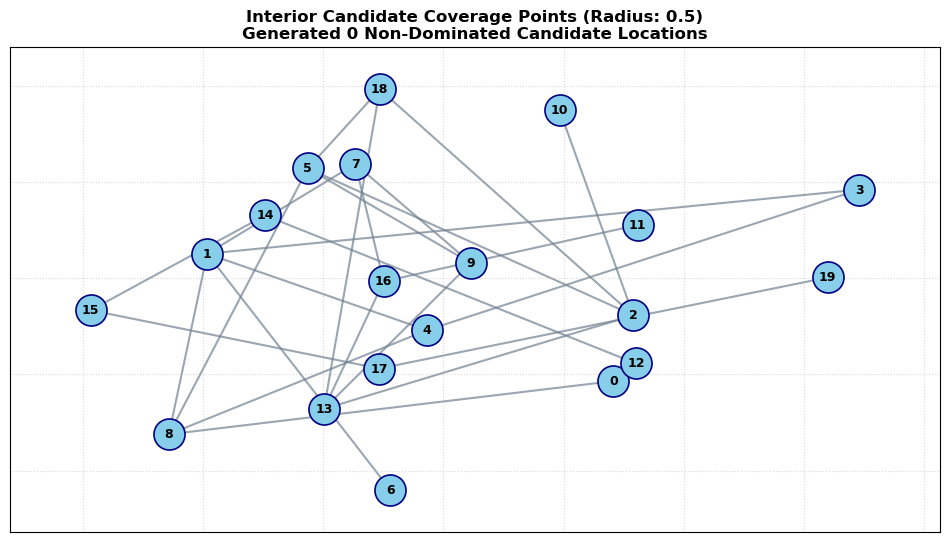

In [42]:
weights = {node: 1.0 for node in G.nodes()}
generator = PointGenerator(pos=pos, weights=weights, coverage_radius=0.5, min_weight=3.0, eps=1.5,)
results = generator.run(G)
generator.generate_candidates()
generator.build_coverage_matrices()
fix, ax = generator.plot_candidates(G)

In [35]:
len(generator.map_to_graph(G))

0